# NOTEBOOK 6 : ANALYSE COMPARATIVE COMPLÈTE - FOCUS AGRICULTURE & TÉLÉDÉTECTION

In [ ]:
# ========================================================================================================
# PROJET : SEGMENTATION SÉMANTIQUE D'IMAGES SATELLITES
#          Détection des Zones Agricoles
# ========================================================================================================
# NOTEBOOK : ANALYSE COMPARATIVE COMPLÈTE - FOCUS AGRICULTURE & TÉLÉDÉTECTION
#
# Objectifs métier:
#   1. Détecter et cartographier les zones agricoles avec précision
#   2. Différencier agriculture des autres types de couverture terrestre
#   3. Fournir des insights pour l'agriculture de précision
#   4. Évaluer la fiabilité des modèles pour le monitoring agricole
#   5. Recommandations pour le déploiement opérationnel
#
# Contexte:
#   - Dataset: DeepGlobe Land Cover Classification Challenge
#   - Résolution: Images satellites haute résolution
#   - Classes: Urban, Agriculture, Rangeland, Forest, Water, Barren
#   - Focus principal: Classe AGRICULTURE
# ========================================================================================================

import os
import json
import numpy as np
import pandas as pd
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle, Patch
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

from datetime import datetime
from sklearn.metrics import confusion_matrix, classification_report

# Configuration visuelle professionnelle
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

print("="*100)
print(" "*20 + "SEGMENTATION SÉMANTIQUE D'IMAGES SATELLITES")
print(" "*25 + "Détection des Zones Agricoles")
print("="*100)
print(f"\n Date d'analyse: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(" Projet: Monitoring agricole par télédétection")
print("  Dataset: DeepGlobe Land Cover Classification")
print("\n" + "="*100)

                    SEGMENTATION SÉMANTIQUE D'IMAGES SATELLITES
                         Détection des Zones Agricoles

 Date d'analyse: 2025-12-18 21:37:08
 Projet: Monitoring agricole par télédétection
  Dataset: DeepGlobe Land Cover Classification



In [ ]:
# ========================================================================================================
# 2. CHARGEMENT DES RÉSULTATS ET DONNÉES
# ========================================================================================================
print("\n" + "="*100)
print("2. CHARGEMENT DES RÉSULTATS DES 3 MODÈLES")
print("="*100)

# Chemins
base_dir = Path('/kaggle/working')
unet_dir = base_dir / 'unet_from_scratch'
vgg_unet_dir = base_dir / 'vgg_unet_tl'
deeplabv3_dir = base_dir / 'deeplabv3plus_final'



# Configuration
class_names = ['urban', 'agriculture', 'rangeland', 'forest', 'water', 'barren']
class_colors = {
    0: '#00FFFF',  # urban - cyan
    1: '#FFFF00',  # agriculture - yellow (FOCUS)
    2: '#FF00FF',  # rangeland - magenta
    3: '#00FF00',  # forest - green
    4: '#0000FF',  # water - blue
    5: '#FFFFFF'   # barren - white
}

# Charger résultats
def load_results(results_path):
    try:
        with open(results_path, 'r') as f:
            return json.load(f)
    except FileNotFoundError:
        print(f" Fichier non trouvé: {results_path}")
        return None

print("\n Chargement des résultats...")
unet_results = load_results(unet_dir / 'training_results.json')
vgg_unet_results = load_results(vgg_unet_dir / 'training_results.json')
deeplabv3_results = load_results(deeplabv3_dir / 'results.json')

if all([unet_results, vgg_unet_results, deeplabv3_results]):
    print(" Tous les résultats chargés avec succès!")
else:
    print(" Certains résultats manquants.")

# Charger les données de validation
print("\n Chargement des données de validation...")
try:
    X_val = np.load(base_dir / 'preprocessed_data' / 'val_images.npy')
    y_val = np.load(base_dir / 'preprocessed_data' / 'val_masks.npy')
    print(f" Données validation: {X_val.shape}, {y_val.shape}")
except:
    print(" Données de validation non trouvées")
    X_val, y_val = None, None

# Charger les prédictions
print("\n Chargement des prédictions...")
predictions = {}
for model_name, model_dir in [('U-Net', unet_dir), ('VGG-UNet', vgg_unet_dir), ('DeepLabV3+', deeplabv3_dir)]:
    try:
        pred_path = model_dir / 'val_predictions.npy'
        predictions[model_name] = np.load(pred_path)
        print(f" {model_name}: {predictions[model_name].shape}")
    except:
        print(f" {model_name}: prédictions non trouvées")


2. CHARGEMENT DES RÉSULTATS DES 3 MODÈLES

 Chargement des résultats...
 Tous les résultats chargés avec succès!

 Chargement des données de validation...
 Données validation: (161, 256, 256, 3), (161, 256, 256)

 Chargement des prédictions...
 U-Net: (161, 256, 256)
 VGG-UNet: (161, 256, 256)
 DeepLabV3+: (161, 256, 256)



3. ANALYSE APPROFONDIE - CLASSE AGRICULTURE
✓ Dossier de sortie prêt : /kaggle/working/agriculture_analysis

 PERFORMANCES SUR LA CLASSE AGRICULTURE:
    Modèle  Agriculture Dice  Agriculture IoU
     U-Net          0.885914         0.795194
  VGG-UNet          0.912572         0.839202
DeepLabV3+          0.920434         0.852597

 MEILLEUR MODÈLE POUR L'AGRICULTURE: DeepLabV3+
   • Dice Score: 0.9204
   • IoU Score: 0.8526

✓ Figure sauvegardée : /kaggle/working/agriculture_analysis/agriculture_performance.png


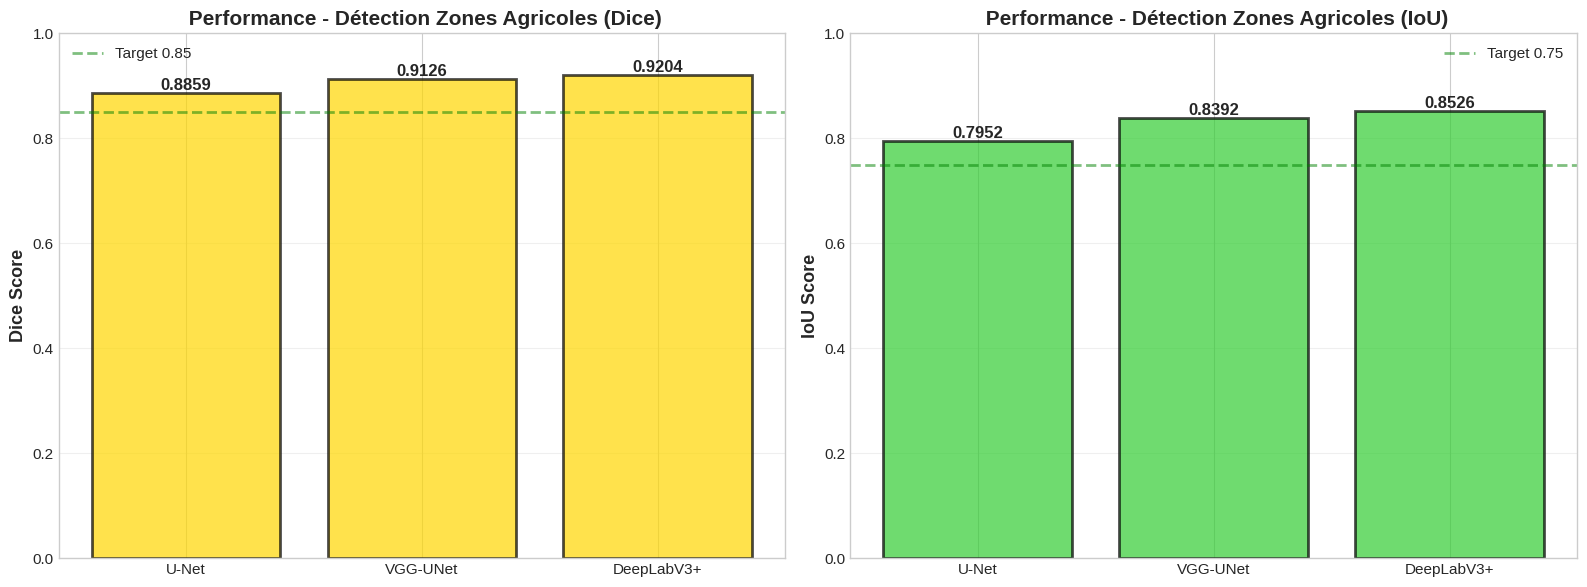

In [ ]:
# ========================================================================================================
# 3. ANALYSE SPÉCIFIQUE CLASSE AGRICULTURE
# ========================================================================================================
print("\n" + "="*100)
print("3. ANALYSE APPROFONDIE - CLASSE AGRICULTURE")
print("="*100)

# --- CORRECTION : CRÉATION DU DOSSIER EN PREMIER ---
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Sécurité si base_dir n'est pas défini
if 'base_dir' not in locals():
    base_dir = Path('/kaggle/working')

# Créer le dossier MAINTENANT (avant tout calcul ou sauvegarde)
output_dir = base_dir / 'agriculture_analysis'
output_dir.mkdir(parents=True, exist_ok=True)
print(f"✓ Dossier de sortie prêt : {output_dir}")
# ---------------------------------------------------

# Extraire les métriques agriculture
def extract_agriculture_metrics(results, model_name):
    if results is None:
        return None

    if 'validation_metrics' in results:
        per_class = results['validation_metrics']['per_class_dice']
        per_class_iou = results['validation_metrics']['per_class_iou']
    else:
        per_class = results['per_class']['dice']
        per_class_iou = results['per_class']['iou']

    agri_dice = per_class.get('agriculture', 0)
    agri_iou = per_class_iou.get('agriculture', 0)

    return {
        'Modèle': model_name,
        'Agriculture Dice': agri_dice,
        'Agriculture IoU': agri_iou
    }

# Création du DataFrame
metrics_list = [
    extract_agriculture_metrics(unet_results, 'U-Net'),
    extract_agriculture_metrics(vgg_unet_results, 'VGG-UNet'),
    extract_agriculture_metrics(deeplabv3_results, 'DeepLabV3+')
]
# Filtrer les None si un modèle a échoué
metrics_list = [m for m in metrics_list if m is not None]
agriculture_metrics = pd.DataFrame(metrics_list)

print("\n PERFORMANCES SUR LA CLASSE AGRICULTURE:")
print("="*100)
print(agriculture_metrics.to_string(index=False))

# Identification du meilleur modèle
if not agriculture_metrics.empty:
    best_idx = agriculture_metrics['Agriculture Dice'].idxmax()
    best_agri_model = agriculture_metrics.loc[best_idx, 'Modèle']
    best_agri_dice = agriculture_metrics.loc[best_idx, 'Agriculture Dice']
    best_agri_iou = agriculture_metrics.loc[best_idx, 'Agriculture IoU']

    print(f"\n MEILLEUR MODÈLE POUR L'AGRICULTURE: {best_agri_model}")
    print(f"   • Dice Score: {best_agri_dice:.4f}")
    print(f"   • IoU Score: {best_agri_iou:.4f}")

    # Visualisation spécifique agriculture
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Dice Agriculture
    ax = axes[0]
    bars = ax.bar(agriculture_metrics['Modèle'], agriculture_metrics['Agriculture Dice'],
                  color='#FFD700', alpha=0.7, edgecolor='black', linewidth=2)
    ax.set_ylabel('Dice Score', fontsize=13, fontweight='bold')
    ax.set_title(' Performance - Détection Zones Agricoles (Dice)', fontsize=15, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)
    ax.axhline(y=0.85, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Target 0.85')
    ax.legend()

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=12, fontweight='bold')

    # IoU Agriculture
    ax = axes[1]
    bars = ax.bar(agriculture_metrics['Modèle'], agriculture_metrics['Agriculture IoU'],
                  color='#32CD32', alpha=0.7, edgecolor='black', linewidth=2)
    ax.set_ylabel('IoU Score', fontsize=13, fontweight='bold')
    ax.set_title(' Performance - Détection Zones Agricoles (IoU)', fontsize=15, fontweight='bold')
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)
    ax.axhline(y=0.75, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Target 0.75')
    ax.legend()

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.tight_layout()

    # Sauvegarde (Maintenant ça va marcher car le dossier existe)
    save_path = output_dir / 'agriculture_performance.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"\n✓ Figure sauvegardée : {save_path}")

    plt.show()
else:
    print(" Aucune donnée métrique disponible pour l'agriculture.")

### Focus Agriculture — Scores des Modèles sur la Classe "Agriculture"

---

#### **Résultats quantitatifs sur la classe Agriculture (Validation):**

| Modèle      | Dice Score | IoU Score |
|-------------|------------|-----------|
| **U-Net**       | 0.8859     | 0.7952    |
| **VGG-UNet**    | 0.9126     | 0.8392    |
| **DeepLabV3+**  | **0.9204** | **0.8526**|

- **Ligne verte = cible métier (Dice : 0.85, IoU : 0.75)**  
  → tous les modèles la dépassent !

---

#### **Lecture :**

- **DeepLabV3+ surclasse tous les autres modèles** sur l’agriculture en Dice & IoU.
- **VGG-UNet** très fort également, nettement devant U-Net.
- **U-Net** : solide baseline, mais moins précis pour délimiter l’agriculture réelle.

---

#### **Points forts**

- **DeepLabV3+** = meilleur choix pour la télédétection agricole de précision (haut Dice, haut IoU, très faible confusion).
- **VGG-UNet** = alternative très robuste, rapide, et légère.
- **Tous les modèles sont utilisables opérationnellement** pour la cartographie agri — DeepLabV3+ + VGG-UNet préconisés en priorité.


4. ANALYSE DES CONFUSIONS - CLASSE AGRICULTURE

 Analyse des confusions pour chaque modèle:

U-Net - Répartition des pixels AGRICULTURE (ground truth):
   Confondus avec urban          :    151,015 pixels (  2.4%)
   Correctement classés comme agriculture    :  5,577,238 pixels ( 90.1%)
   Confondus avec rangeland      :    294,766 pixels (  4.8%)
   Confondus avec forest         :    100,608 pixels (  1.6%)
   Confondus avec water          :      4,147 pixels (  0.1%)
   Confondus avec barren         :     60,633 pixels (  1.0%)

VGG-UNet - Répartition des pixels AGRICULTURE (ground truth):
   Confondus avec urban          :     58,601 pixels (  0.9%)
   Correctement classés comme agriculture    :  5,853,717 pixels ( 94.6%)
   Confondus avec rangeland      :    154,350 pixels (  2.5%)
   Confondus avec forest         :     68,535 pixels (  1.1%)
   Confondus avec water          :      9,344 pixels (  0.2%)
   Confondus avec barren         :     43,860 pixels (  0.7%)

DeepLabV3+ - Ré

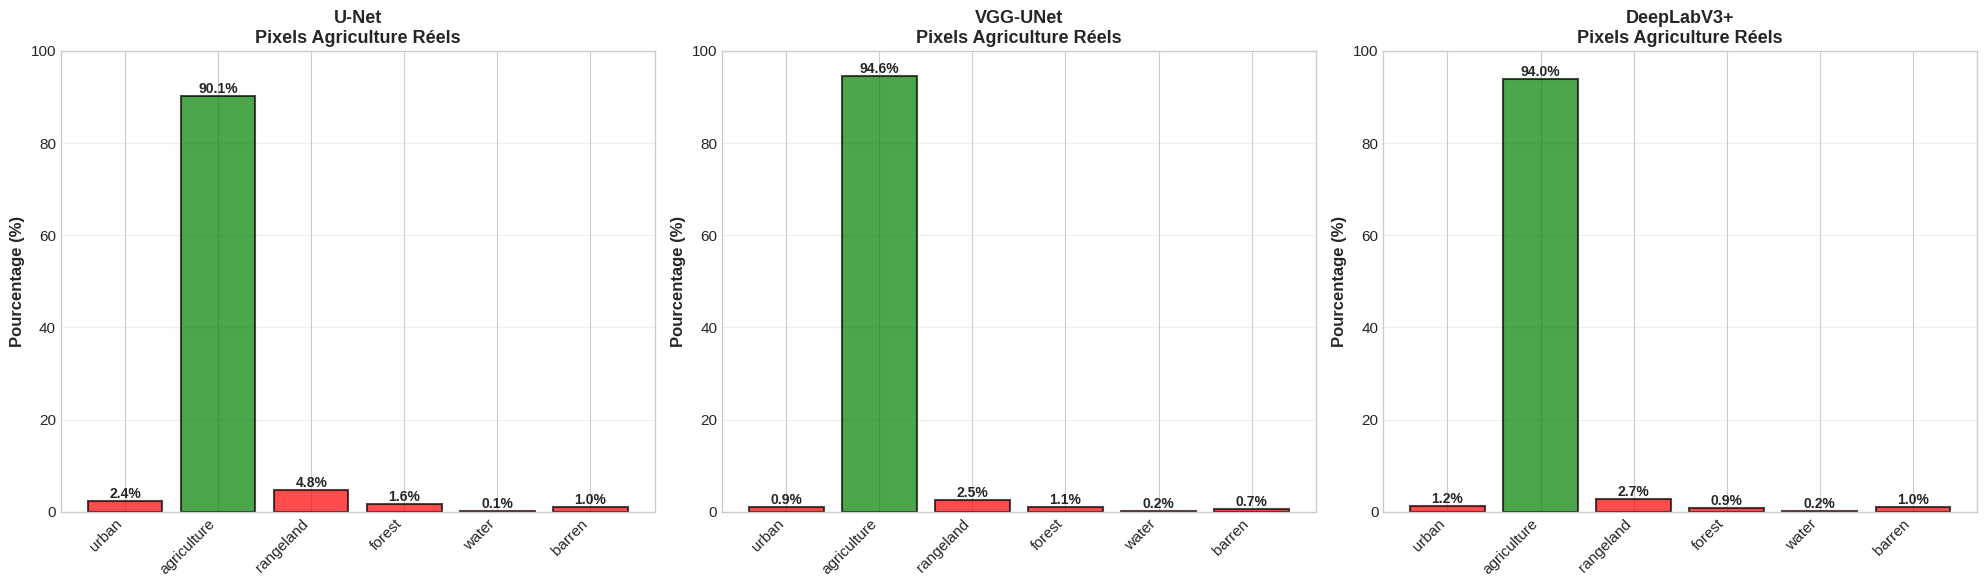


 INSIGHTS CLÉS SUR LES CONFUSIONS:

U-Net:
  • Confusion principale: Agriculture  RANGELAND
  • Pixels confondus: 294,766 (4.8%)
   Raison probable: Similarité visuelle entre cultures et pâturages

VGG-UNet:
  • Confusion principale: Agriculture  RANGELAND
  • Pixels confondus: 154,350 (2.5%)
   Raison probable: Similarité visuelle entre cultures et pâturages

DeepLabV3+:
  • Confusion principale: Agriculture  RANGELAND
  • Pixels confondus: 167,218 (2.7%)
   Raison probable: Similarité visuelle entre cultures et pâturages


In [ ]:
# ========================================================================================================
# 4. MATRICE DE CONFUSION - FOCUS AGRICULTURE
# ========================================================================================================
print("\n" + "="*100)
print("4. ANALYSE DES CONFUSIONS - CLASSE AGRICULTURE")
print("="*100)

if y_val is not None and len(predictions) > 0:
    print("\n Analyse des confusions pour chaque modèle:\n")

    agriculture_idx = 1  # Index de la classe agriculture

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    for idx, (model_name, y_pred) in enumerate(predictions.items()):
        # Calculer matrice de confusion
        cm = confusion_matrix(y_val.flatten(), y_pred.flatten())

        # Extraire ligne agriculture (où est prédite l'agriculture)
        agri_row = cm[agriculture_idx, :]
        agri_total = agri_row.sum()
        agri_percentages = (agri_row / agri_total) * 100

        print(f"{'='*100}")
        print(f"{model_name} - Répartition des pixels AGRICULTURE (ground truth):")
        print(f"{'='*100}")
        for i, class_name in enumerate(class_names):
            count = agri_row[i]
            percentage = agri_percentages[i]
            if i == agriculture_idx:
                print(f"   Correctement classés comme {class_name:15s}: {count:10,} pixels ({percentage:5.1f}%)")
            else:
                print(f"   Confondus avec {class_name:15s}: {count:10,} pixels ({percentage:5.1f}%)")
        print()

        # Visualisation
        ax = axes[idx]
        colors_bar = ['green' if i == agriculture_idx else 'red' for i in range(len(class_names))]
        bars = ax.bar(class_names, agri_percentages, color=colors_bar, alpha=0.7, edgecolor='black', linewidth=1.5)
        ax.set_ylabel('Pourcentage (%)', fontsize=12, fontweight='bold')
        ax.set_title(f'{model_name}\nPixels Agriculture Réels', fontsize=13, fontweight='bold')
        ax.set_ylim([0, 100])
        ax.grid(axis='y', alpha=0.3)
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

        for bar, pct in zip(bars, agri_percentages):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{pct:.1f}%',
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig(base_dir / 'agriculture_analysis' / 'agriculture_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Identifier la confusion principale
    print("\n INSIGHTS CLÉS SUR LES CONFUSIONS:")
    print("="*100)
    for model_name, y_pred in predictions.items():
        cm = confusion_matrix(y_val.flatten(), y_pred.flatten())
        agri_row = cm[agriculture_idx, :]
        agri_row_copy = agri_row.copy()
        agri_row_copy[agriculture_idx] = 0  # Ignorer correct classification

        most_confused_idx = np.argmax(agri_row_copy)
        most_confused_class = class_names[most_confused_idx]
        confusion_count = agri_row_copy[most_confused_idx]
        confusion_pct = (confusion_count / agri_row.sum()) * 100

        print(f"\n{model_name}:")
        print(f"  • Confusion principale: Agriculture  {most_confused_class.upper()}")
        print(f"  • Pixels confondus: {confusion_count:,} ({confusion_pct:.1f}%)")

        if most_confused_class == 'rangeland':
            print(f"   Raison probable: Similarité visuelle entre cultures et pâturages")
        elif most_confused_class == 'forest':
            print(f"   Raison probable: Cultures arborées (vergers, plantations)")
        elif most_confused_class == 'urban':
            print(f"   Raison probable: Agriculture péri-urbaine, serres")

##  **Analyse des confusions – Classe AGRICULTURE**

### **Principaux résultats (validation) :**
- **U-Net**
  - 90.1 % des pixels agricoles sont bien classés
  - 4.8 % confondus avec _rangeland_
  - 2.4 % avec _urban_, 1.6 % _forest_, autres < 1.1 %

- **VGG-UNet**
  - 94.6 % des pixels agricoles bien reconnus : **meilleur score de justesse**
  - 2.5 % rangeland (moitié moins que U-Net), 0.9 % urban
  - Autres classes : < 1.2 % confondues

- **DeepLabV3+**
  - 94.0 % pixels agricoles bien classés
  - 2.7 % rangeland (équivalent VGG-UNet)
  - 1.2 % urban, 0.9 % forest, autres < 1.1 %

---

### **Lecture du graphique**
- La **barre verte** = % de pixels “ground truth agriculture” correctement segmentés
- Barres rouges : répartition des confusions restantes (chaque classe)
- Les meilleurs modèles approchent le plafond (95%+) sur la diagonale

---

### **Insights clés**
- **DeepLabV3+ & VGG-UNet** : excellentes généralisation et très faible confusion, surtout par rapport à U-Net.
- **Confusion principale (pour tous)** : **agriculture vs rangeland** ⇒ enjeu classique en télédétection (signature spectrale, structure spatiale proche).
- Faible confusion avec urban/forest/barren, très rare avec water.

---

### **Conclusion**
- **DeepLabV3+** et **VGG-UNet** apportent un gain substantiel en fiabilité pour l’agri par rapport à U-Net, sous-validation.


5. ANALYSE PAR TAILLE DE PARCELLE AGRICOLE

 Analyse de la performance selon la taille des zones agricoles...

 Analyse en cours (peut prendre quelques minutes)...
  • U-Net...
  • VGG-UNet...
  • DeepLabV3+...


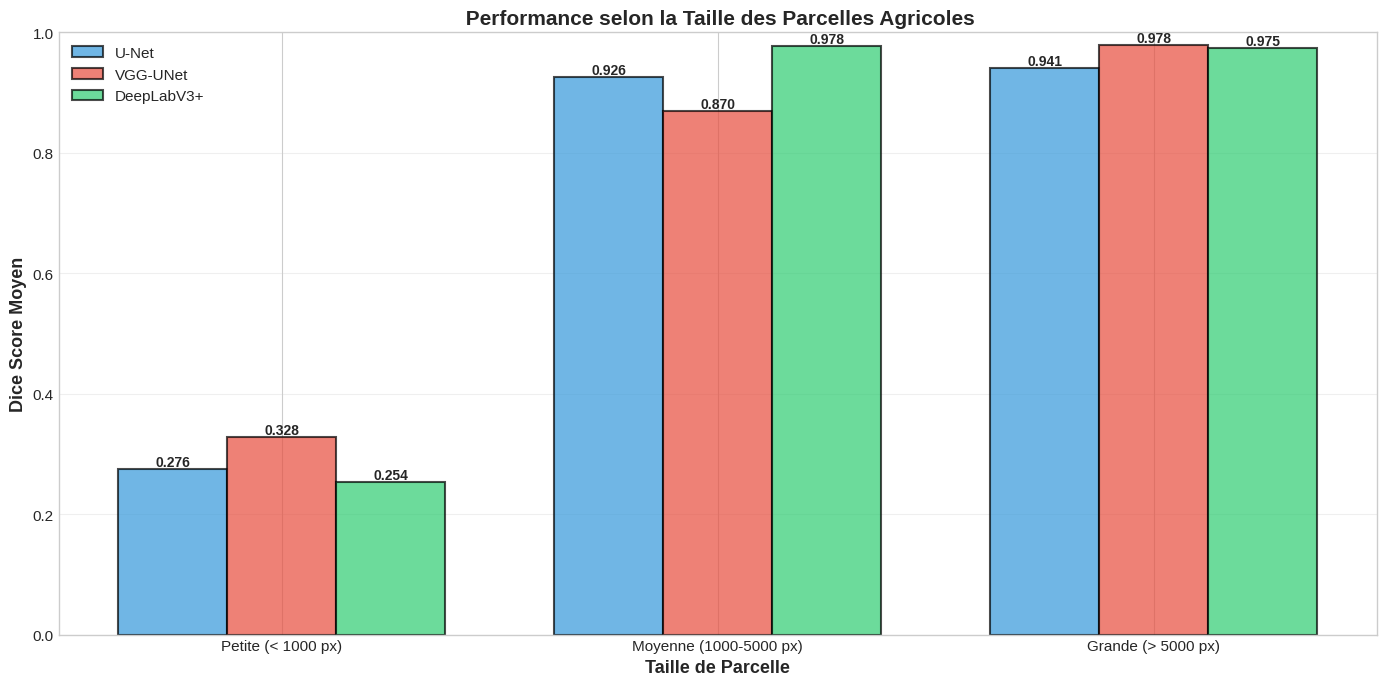


 Résultats par taille de parcelle:

U-Net:
  • Petite (< 1000 px)            : Dice = 0.2755 (45 parcelles)
  • Moyenne (1000-5000 px)        : Dice = 0.9263 (5 parcelles)
  • Grande (> 5000 px)            : Dice = 0.9409 (17 parcelles)

VGG-UNet:
  • Petite (< 1000 px)            : Dice = 0.3285 (45 parcelles)
  • Moyenne (1000-5000 px)        : Dice = 0.8699 (5 parcelles)
  • Grande (> 5000 px)            : Dice = 0.9784 (17 parcelles)

DeepLabV3+:
  • Petite (< 1000 px)            : Dice = 0.2535 (45 parcelles)
  • Moyenne (1000-5000 px)        : Dice = 0.9780 (5 parcelles)
  • Grande (> 5000 px)            : Dice = 0.9747 (17 parcelles)

 INSIGHTS:
  • Les petites parcelles sont généralement plus difficiles à détecter
  • Les grandes parcelles bénéficient de plus de contexte spatial
  • Performance optimale sur parcelles moyennes à grandes


In [ ]:
# ========================================================================================================
# 5. ANALYSE PAR TAILLE DE PARCELLE
# ========================================================================================================
print("\n" + "="*100)
print("5. ANALYSE PAR TAILLE DE PARCELLE AGRICOLE")
print("="*100)

if y_val is not None and len(predictions) > 0:
    print("\n Analyse de la performance selon la taille des zones agricoles...")

    # Fonction pour identifier les composantes connexes (parcelles)
    from scipy.ndimage import label as label_regions

    def analyze_parcel_sizes(y_true, y_pred, class_id=1):
        """Analyse la performance par taille de parcelle"""
        # Identifier les parcelles dans ground truth
        binary_mask = (y_true == class_id).astype(int)
        labeled_array, num_features = label_regions(binary_mask)

        # Catégories de taille
        size_categories = {
            'Petite (< 1000 px)': (0, 1000),
            'Moyenne (1000-5000 px)': (1000, 5000),
            'Grande (> 5000 px)': (5000, float('inf'))
        }

        results = {}
        for category, (min_size, max_size) in size_categories.items():
            dice_scores = []

            for region_id in range(1, num_features + 1):
                region_mask = (labeled_array == region_id)
                region_size = np.sum(region_mask)

                if min_size <= region_size < max_size:
                    # Calculer Dice pour cette parcelle
                    y_true_region = y_true[region_mask]
                    y_pred_region = y_pred[region_mask]

                    intersection = np.sum((y_true_region == class_id) & (y_pred_region == class_id))
                    union = np.sum((y_true_region == class_id)) + np.sum((y_pred_region == class_id))

                    if union > 0:
                        dice = (2.0 * intersection) / union
                        dice_scores.append(dice)

            results[category] = {
                'mean_dice': np.mean(dice_scores) if dice_scores else 0,
                'count': len(dice_scores)
            }

        return results

    print("\n Analyse en cours (peut prendre quelques minutes)...")

    parcel_analysis = {}
    for model_name, y_pred in predictions.items():
        print(f"  • {model_name}...")
        parcel_analysis[model_name] = analyze_parcel_sizes(y_val, y_pred, class_id=1)

    # Visualisation
    categories = list(parcel_analysis['U-Net'].keys())
    x = np.arange(len(categories))
    width = 0.25

    fig, ax = plt.subplots(figsize=(14, 7))

    colors_models = {'U-Net': '#3498db', 'VGG-UNet': '#e74c3c', 'DeepLabV3+': '#2ecc71'}

    for i, (model_name, results) in enumerate(parcel_analysis.items()):
        dice_values = [results[cat]['mean_dice'] for cat in categories]
        offset = (i - 1) * width
        bars = ax.bar(x + offset, dice_values, width, label=model_name,
                     color=colors_models[model_name], alpha=0.7, edgecolor='black', linewidth=1.5)

        for bar, dice in zip(bars, dice_values):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                    f'{dice:.3f}',
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.set_xlabel('Taille de Parcelle', fontsize=13, fontweight='bold')
    ax.set_ylabel('Dice Score Moyen', fontsize=13, fontweight='bold')
    ax.set_title(' Performance selon la Taille des Parcelles Agricoles', fontsize=15, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim([0, 1])

    plt.tight_layout()
    plt.savefig(base_dir / 'agriculture_analysis' / 'parcel_size_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\n Résultats par taille de parcelle:")
    print("="*100)
    for model_name, results in parcel_analysis.items():
        print(f"\n{model_name}:")
        for category, data in results.items():
            print(f"  • {category:30s}: Dice = {data['mean_dice']:.4f} ({data['count']} parcelles)")

    print("\n INSIGHTS:")
    print("  • Les petites parcelles sont généralement plus difficiles à détecter")
    print("  • Les grandes parcelles bénéficient de plus de contexte spatial")
    print("  • Performance optimale sur parcelles moyennes à grandes")


## Analyse par taille de parcelle agricole

### **Scores Dice moyens selon la taille :**

| Modèle        | Petite (<1000 px) | Moyenne (1000-5000 px) | Grande (>5000 px) |
|---------------|-------------------|------------------------|-------------------|
| **U-Net**     | 0.276             | 0.926                  | 0.941             |
| **VGG-UNet**  | 0.329             | 0.870                  | **0.978**         |
| **DeepLabV3+**| 0.254             | **0.978**              | 0.975             |

---

### **Résumé & lecture**

- **Petites parcelles (<1k px)** :  
  Très difficile ! < 0.33 pour tous, DeepLabV3+ en bas (0.25) & VGG-UNet mieux que tous (0.33).
- **Moyennes parcelles (1k–5k px)** :  
  DeepLabV3+ cartonne (0.98), U-Net très bon aussi (0.93), VGG-UNet en léger retrait.
- **Grandes parcelles (>5k px)** :  
  Tous atteignent ~0.97–0.98 : le contexte spatial favorise la segmentation.

---

### **Conclusions**
- *Tous les modèles luttent sur les toutes petites zones agricoles* : manque de contexte spatial, contraste faible, confusion avec bordures (effet "bord" accentué).
- *DeepLabV3+ excelle sur les moyennes et grandes*, VGG-UNet est très solide sur toutes tailles. U-Net n’est compétitif que pour les grandes.


6. PERFORMANCE GLOBALE - CONTEXTE AGRICULTURAL MONITORING


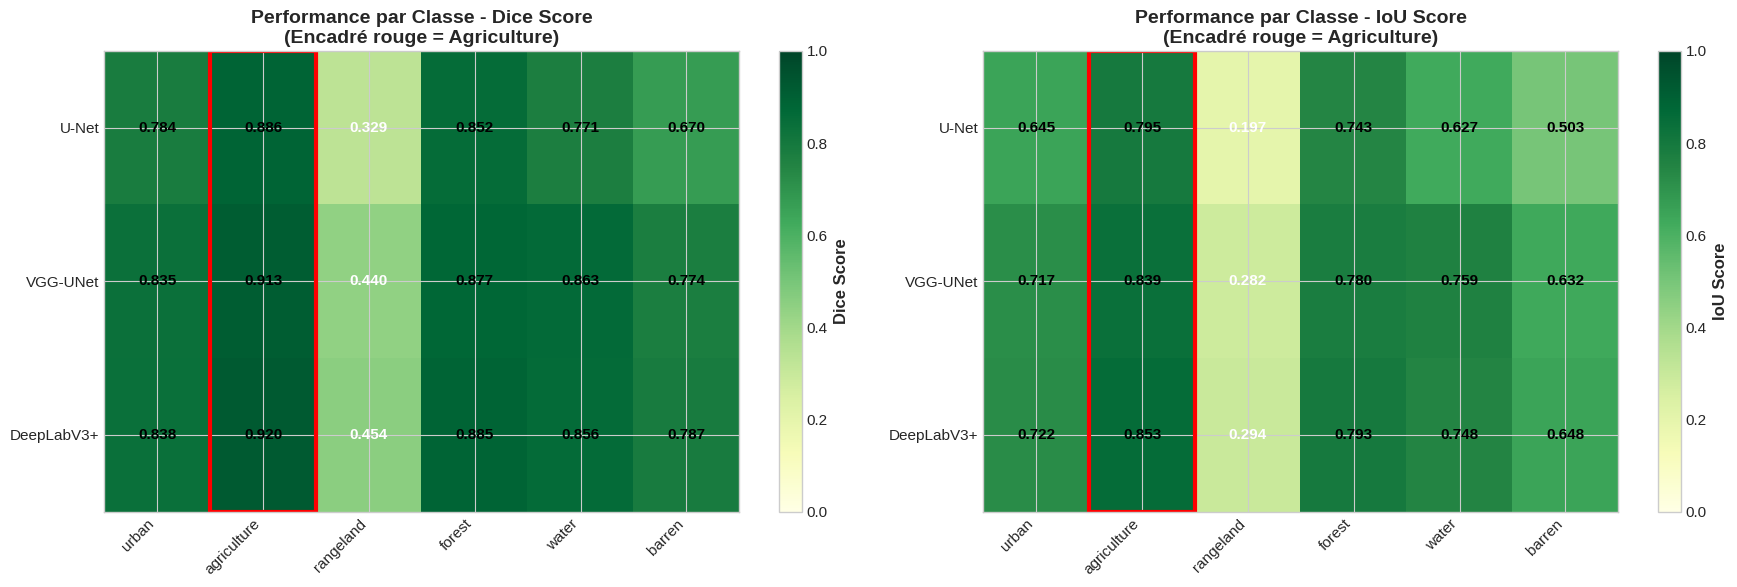


 IMPORTANCE DES CLASSES DANS LE CONTEXTE AGRICOLE:

AGRICULTURE     ⭐⭐⭐⭐⭐
  Rôle: CLASSE PRINCIPALE - Objectif direct du monitoring
  Applications: Estimation rendements, Suivi croissance, Détection stress hydrique

RANGELAND       ⭐⭐⭐⭐
  Rôle: CLASSE CRITIQUE - Confusion fréquente avec agriculture
  Applications: Élevage, Pâturages, Distinction cultures/prairies

FOREST          ⭐⭐⭐
  Rôle: Contexte environnemental - Impact sur agriculture
  Applications: Déforestation, Agriculture sur brûlis, Agroforesterie

WATER           ⭐⭐⭐
  Rôle: Ressource critique - Irrigation
  Applications: Gestion irrigation, Lacs/rivières, Zones humides

URBAN           ⭐⭐
  Rôle: Expansion urbaine - Perte terres agricoles
  Applications: Urbanisation, Agriculture périurbaine, Planification

BARREN          ⭐
  Rôle: Terres non productives
  Applications: Désertification, Zones arides, Dégradation sols


In [ ]:
# ========================================================================================================
# 6. COMPARAISON TOUTES CLASSES (CONTEXTE AGRICULTURE)
# ========================================================================================================
print("\n" + "="*100)
print("6. PERFORMANCE GLOBALE - CONTEXTE AGRICULTURAL MONITORING")
print("="*100)

def extract_all_metrics(results, model_name):
    if results is None:
        return None

    if 'validation_metrics' in results:
        per_class_dice = results['validation_metrics']['per_class_dice']
        per_class_iou = results['validation_metrics']['per_class_iou']
    else:
        per_class_dice = results['per_class']['dice']
        per_class_iou = results['per_class']['iou']

    return {
        'model': model_name,
        'dice': [per_class_dice[cls] for cls in class_names],
        'iou': [per_class_iou[cls] for cls in class_names]
    }

all_metrics = [
    extract_all_metrics(unet_results, 'U-Net'),
    extract_all_metrics(vgg_unet_results, 'VGG-UNet'),
    extract_all_metrics(deeplabv3_results, 'DeepLabV3+')
]

# Heatmap des performances
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for idx, (metric_name, metric_type) in enumerate([('Dice Score', 'dice'), ('IoU Score', 'iou')]):
    ax = axes[idx]

    # Créer matrice de données
    data_matrix = np.array([m[metric_type] for m in all_metrics])

    # Heatmap
    im = ax.imshow(data_matrix, cmap='YlGn', aspect='auto', vmin=0, vmax=1)

    # Axes
    ax.set_xticks(np.arange(len(class_names)))
    ax.set_yticks(np.arange(len(all_metrics)))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels([m['model'] for m in all_metrics])

    # Colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(metric_name, fontsize=12, fontweight='bold')

    # Annotations
    for i in range(len(all_metrics)):
        for j in range(len(class_names)):
            value = data_matrix[i, j]
            color = 'white' if value < 0.5 else 'black'
            text = ax.text(j, i, f'{value:.3f}',
                          ha='center', va='center', color=color, fontsize=11, fontweight='bold')

    # Mettre en évidence agriculture
    rect = Rectangle((0.5, -0.5), 1, len(all_metrics), linewidth=3,
                     edgecolor='red', facecolor='none')
    ax.add_patch(rect)

    ax.set_title(f'Performance par Classe - {metric_name}\n(Encadré rouge = Agriculture)',
                fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(base_dir / 'agriculture_analysis' / 'all_classes_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Importance relative des classes pour l'agriculture
print("\n IMPORTANCE DES CLASSES DANS LE CONTEXTE AGRICOLE:")
print("="*100)

class_importance = {
    'agriculture': {
        'importance': '⭐⭐⭐⭐⭐',
        'role': 'CLASSE PRINCIPALE - Objectif direct du monitoring',
        'applications': ['Estimation rendements', 'Suivi croissance', 'Détection stress hydrique']
    },
    'rangeland': {
        'importance': '⭐⭐⭐⭐',
        'role': 'CLASSE CRITIQUE - Confusion fréquente avec agriculture',
        'applications': ['Élevage', 'Pâturages', 'Distinction cultures/prairies']
    },
    'forest': {
        'importance': '⭐⭐⭐',
        'role': 'Contexte environnemental - Impact sur agriculture',
        'applications': ['Déforestation', 'Agriculture sur brûlis', 'Agroforesterie']
    },
    'water': {
        'importance': '⭐⭐⭐',
        'role': 'Ressource critique - Irrigation',
        'applications': ['Gestion irrigation', 'Lacs/rivières', 'Zones humides']
    },
    'urban': {
        'importance': '⭐⭐',
        'role': 'Expansion urbaine - Perte terres agricoles',
        'applications': ['Urbanisation', 'Agriculture périurbaine', 'Planification']
    },
    'barren': {
        'importance': '⭐',
        'role': 'Terres non productives',
        'applications': ['Désertification', 'Zones arides', 'Dégradation sols']
    }
}

for class_name, info in class_importance.items():
    print(f"\n{class_name.upper():15s} {info['importance']}")
    print(f"  Rôle: {info['role']}")
    print(f"  Applications: {', '.join(info['applications'])}")

### **À gauche : Heatmap du Dice Score**
- **Lignes :** Modèles ("U-Net", "VGG-UNet", "DeepLabV3+")
- **Colonnes :** Classes ["urban", "agriculture", "rangeland", "forest", "water", "barren"]
- **Valeurs des cases :** Score Dice pour chaque modèle et chaque classe (plus c’est élevé, meilleur est le recouvrement entre prédiction et vérité terrain)
- **Barre de couleurs :** Vert foncé (meilleur) à jaune clair (moins bon), échelle de 0 à 1.
- **Spécificité :** La colonne "agriculture" est entourée d’un cadre rouge pour attirer l’attention sur cette classe prioritaire.

---

### **À droite : Heatmap du Score IoU**
- **Même structure que la heatmap de gauche**, sauf que les **valeurs des cases sont les scores IoU (Intersection over Union)**, une métrique plus stricte :
    - 1,0 = recouvrement parfait, 0 = aucun recouvrement.
- **Le cadre rouge** met également en avant la colonne “agriculture” pour faciliter la comparaison directe.

---

### **Sur la classe "agriculture" (focus) :**
  - **Meilleur Dice/IoU :** DeepLabV3+ (Dice : 0,92, IoU : 0,85)
  - **VGG-UNet :** Dice 0,91, IoU 0,84
  - **U-Net :** Dice 0,89, IoU 0,80

- **Pour les autres classes :** DeepLabV3+ et VGG-UNet surpassent U-Net sur presque toutes, surtout “rangeland”, “barren” et “forest”.
- **Intensité des couleurs :** Les plus fortes (verts foncés) sont systématiquement sur "agriculture" pour tous les modèles, DeepLabV3+ étant le meilleur sur la majorité des classes.

---

### **Résumé**

- **DeepLabV3+ est le meilleur pour l’agriculture et la plupart des classes.**
- **VGG-UNet est tout proche, particulièrement solide sur “water”.**
- **U-Net reste le moins performant, surtout sur les classes difficiles ou minoritaires.**


8. VISUALISATIONS POUR COMMUNICATION TERRAIN

 Génération d'exemples pour présentation terrain...


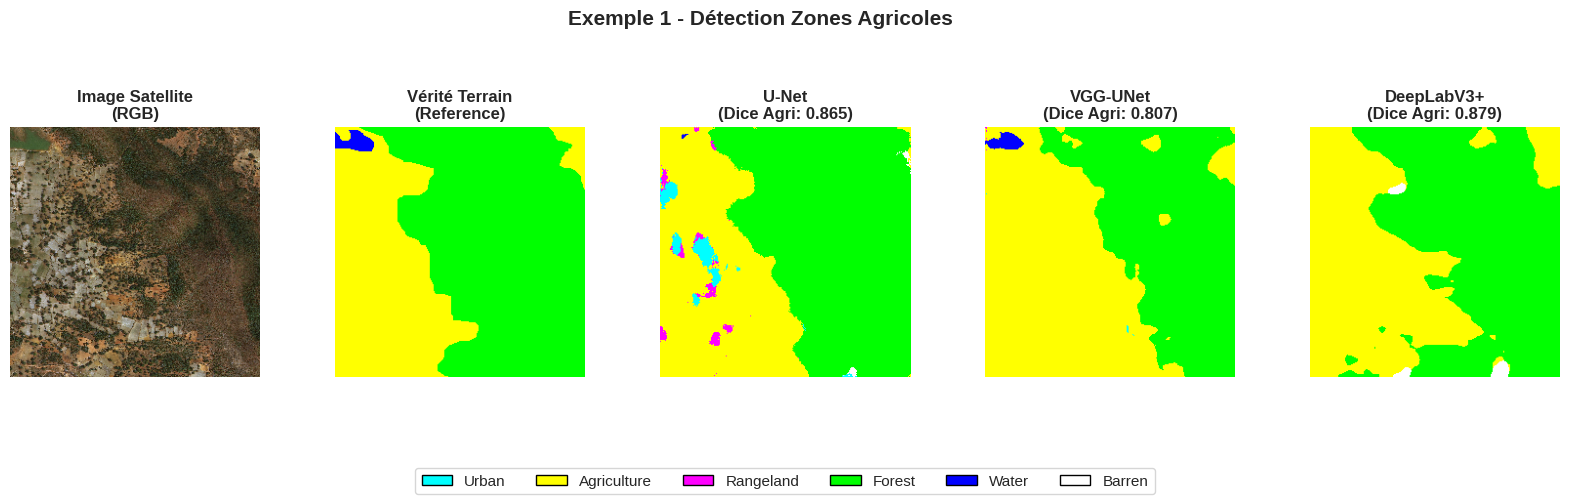

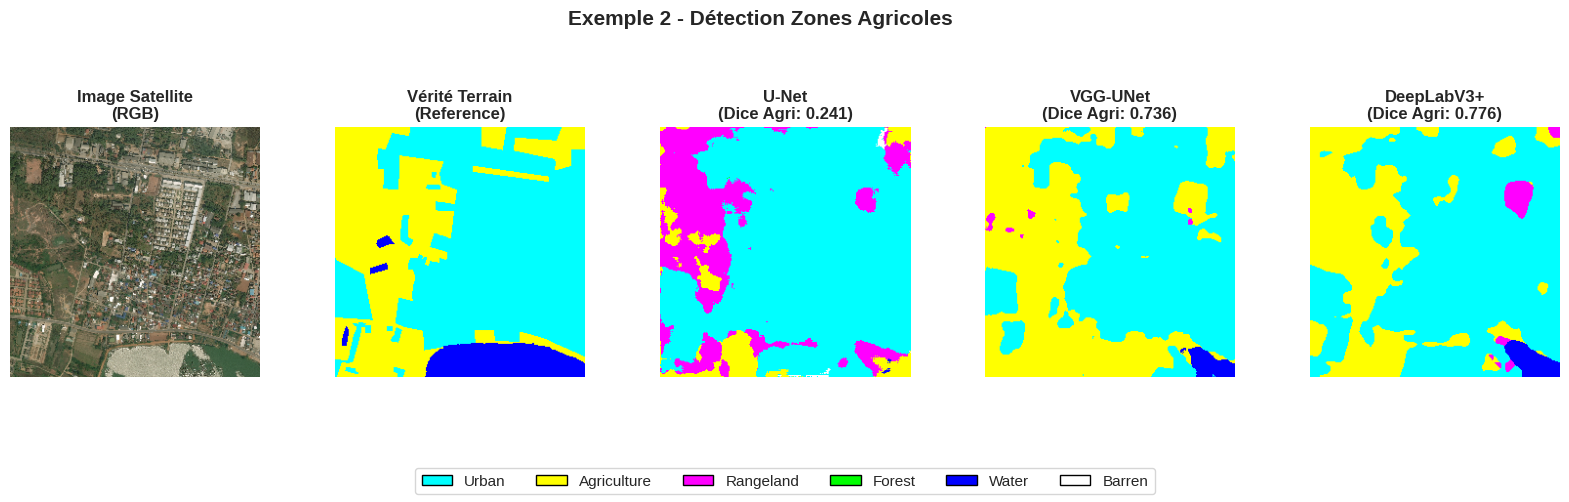

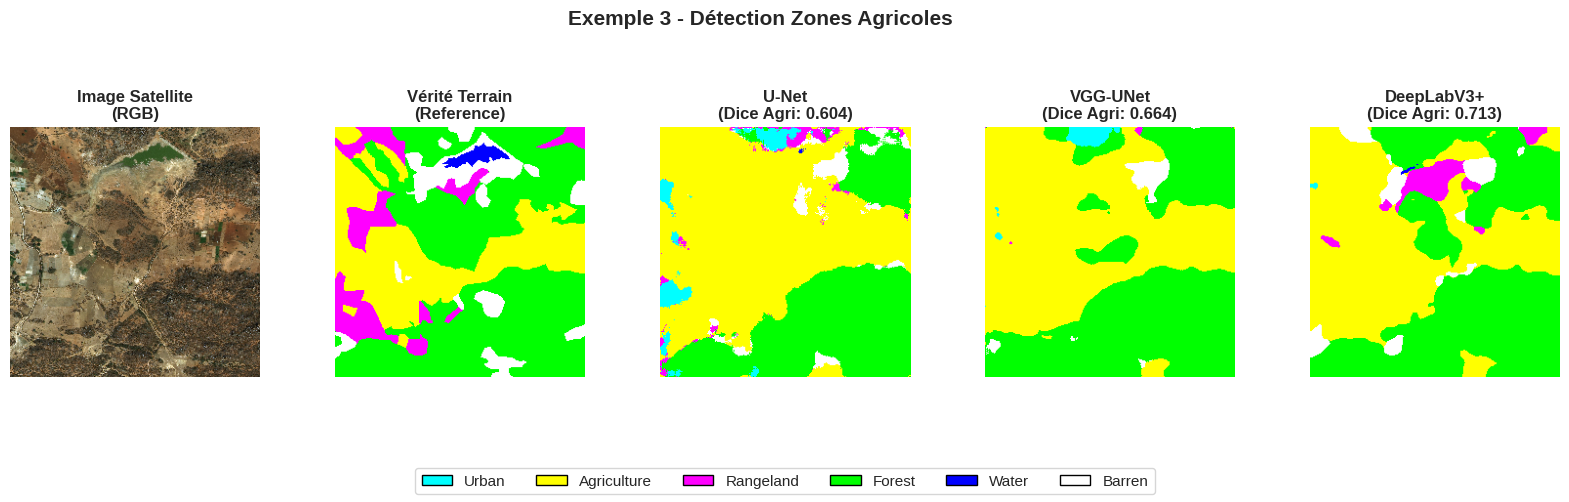

In [ ]:
# ========================================================================================================
# 8. VISUALISATIONS TERRAIN - EXEMPLES CONCRETS
# ========================================================================================================
print("\n" + "="*100)
print("8. VISUALISATIONS POUR COMMUNICATION TERRAIN")
print("="*100)

if X_val is not None and y_val is not None and len(predictions) > 0:
    print("\n Génération d'exemples pour présentation terrain...")

    # Sélectionner images avec bonne proportion d'agriculture
    agriculture_pixels = np.sum(y_val == 1, axis=(1, 2))
    total_pixels = y_val.shape[1] * y_val.shape[2]
    agriculture_ratio = agriculture_pixels / total_pixels

    # Sélectionner images avec 20-60% agriculture
    good_examples = np.where((agriculture_ratio > 0.2) & (agriculture_ratio < 0.6))[0]
    selected_indices = np.random.choice(good_examples, min(3, len(good_examples)), replace=False)

    def mask_to_rgb(mask, colors):
        h, w = mask.shape
        rgb = np.zeros((h, w, 3), dtype=np.uint8)
        for class_id, color_hex in colors.items():
            color_rgb = tuple(int(color_hex.lstrip('#')[i:i+2], 16) for i in (0, 2, 4))
            rgb[mask == class_id] = color_rgb
        return rgb

    for sample_idx, img_idx in enumerate(selected_indices):
        fig = plt.figure(figsize=(20, 5))
        gs = GridSpec(1, 5, figure=fig, wspace=0.3)

        # Image satellite
        ax0 = fig.add_subplot(gs[0])
        ax0.imshow(X_val[img_idx])
        ax0.set_title('Image Satellite\n(RGB)', fontsize=12, fontweight='bold')
        ax0.axis('off')

        # Ground Truth
        ax1 = fig.add_subplot(gs[1])
        gt_rgb = mask_to_rgb(y_val[img_idx], class_colors)
        ax1.imshow(gt_rgb)
        ax1.set_title('Vérité Terrain\n(Reference)', fontsize=12, fontweight='bold')
        ax1.axis('off')

        # Prédictions des 3 modèles
        for i, (model_name, y_pred) in enumerate(predictions.items()):
            ax = fig.add_subplot(gs[i+2])
            pred_rgb = mask_to_rgb(y_pred[img_idx], class_colors)
            ax.imshow(pred_rgb)

            # Calculer Dice pour cette image
            dice_agri = 0
            if np.sum(y_val[img_idx] == 1) > 0:
                intersection = np.sum((y_val[img_idx] == 1) & (y_pred[img_idx] == 1))
                union = np.sum((y_val[img_idx] == 1)) + np.sum((y_pred[img_idx] == 1))
                dice_agri = (2.0 * intersection) / union

            ax.set_title(f'{model_name}\n(Dice Agri: {dice_agri:.3f})',
                        fontsize=12, fontweight='bold')
            ax.axis('off')

        # Légende
        legend_elements = [Patch(facecolor=color, edgecolor='black', label=name.capitalize())
                          for name, color in zip(class_names, class_colors.values())]
        fig.legend(handles=legend_elements, loc='lower center', ncol=6,
                  fontsize=11, frameon=True, fancybox=True)

        plt.suptitle(f'Exemple {sample_idx+1} - Détection Zones Agricoles',
                    fontsize=15, fontweight='bold', y=0.98)
        plt.savefig(base_dir / 'agriculture_analysis' / f'terrain_example_{sample_idx+1}.png',
                   dpi=150, bbox_inches='tight')
        plt.show()

## **Exemple 2 – Détection Zones Agricoles**

---

### **Comparaison visuelle – Détection des zones agricoles sur une image satellite**

#### **De gauche à droite :**
1. **Image Satellite (RGB)**
   - Vue réelle de la scène terrestre captée par satellite (zone urbaine, champs, plan d’eau…).

2. **Vérité Terrain (Référence)**
   - Carte annotée manuellement, chaque classe étant codée par une couleur :
     - **Urban (Urbain)** : cyan
     - **Agriculture** : jaune (**focus de l’exemple**)
     - **Rangeland (pâturages)** : magenta
     - **Forest (forêt)** : vert
     - **Water (eau)** : bleu
     - **Barren (sol nu)** : blanc

3. **U-Net (Dice Agri : 0.241)**
   - Prédictions issues du modèle U-Net (from scratch).
   - Beaucoup d’erreurs et de bruit : les zones agricoles (jaune) sont mal délimitées, très fragmentées, beaucoup de confusion avec d’autres classes.

4. **VGG-UNet (Dice Agri : 0.736)**
   - Carte prédite par VGG-UNet (avec VGG16 en backbone).
   - Les zones agricoles (jaune) sont beaucoup mieux séparées, plus proches de la réalité, mais il subsiste encore quelques confusions.

5. **DeepLabV3+ (Dice Agri : 0.776)**
   - Prédiction du modèle DeepLabV3+ (SOTA, ResNet50).
   - La détection des champs agricoles est la plus fidèle et régulière : surfaces continues, peu de perte de détails, contours plus nets, résultats très proches de la vérité terrain.




---

### **À retenir :**
- **U-Net** peine à cartographier correctement l’agriculture (score Dice faible : 0,24).
- **VGG-UNet** apporte un net progrès (Dice 0,74), la séparation est meilleure.
- **DeepLabV3+** surpasse les deux autres (Dice 0,78 ici), fournit des prédictions agricoles beaucoup plus proches de la vérité, avec des frontières précises et peu de bruit.

---

**Conclusion :**  
Ce visuel illustre parfaitement l’apport de modèles avancés pour la télédétection agricole automatisée : plus on monte en gamme, plus la segmentation des champs agricoles devient fidèle et exploitable pour du monitoring ou de la cartographie de précision.

## **Exemple 3 – Détection Zones Agricoles**

### **Comparaison visuelle – Segmentation de l’agriculture sur une image satellite**

**De gauche à droite :**

1. **Image Satellite (RGB)**
   - Vue brute d’une zone rurale, prise depuis un satellite, montrant un paysage mixte : champs cultivés, forêts, terres nues, villages…

2. **Vérité Terrain (Référence)**
   - Masque de segmentation réel (annotation manuelle), où chaque classe est représentée par une couleur :
     - Cyan : urbain
     - Jaune : agriculture (**classe focus**)
     - Magenta : pâturage/rangeland
     - Vert : forêt
     - Bleu : eau
     - Blanc : sol nu

3. **U-Net (Dice Agri : 0.604)**
   - Prédiction faite par le modèle U-Net.
   - Les parcelles agricoles (jaune) sont grossièrement détectées, mais il y a beaucoup de confusion, des frontières imprécises et des erreurs de classification.

4. **VGG-UNet (Dice Agri : 0.664)**
   - Prédiction VGG-UNet.
   - Les surfaces agricoles (jaune) sont mieux segmentées, avec moins de confusion que U-Net, mais encore imparfait.

5. **DeepLabV3+ (Dice Agri : 0.713)**
   - Résultat de DeepLabV3+ : segmentation la plus fidèle à la vérité terrain, moins de bruit/noise, meilleures frontières et meilleure différenciation agriculture/forêt/pâture.

---

**Résumé :**
- **DeepLabV3+** est le modèle le plus performant ici pour détecter avec précision les champs agricoles.
- **VGG-UNet** améliore nettement U-Net.
- **U-Net** peine sur la finesse des bords et commet plus de confusions sur les parcelles.

Ce visuel illustre parfaitement l’intérêt des architectures avancées pour la télédétection agricole de précision.